## Importing the necessary Libraries ##

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)

## Loading the make_moons datasets

X shape: (500, 2)
y shape: (500, 1)


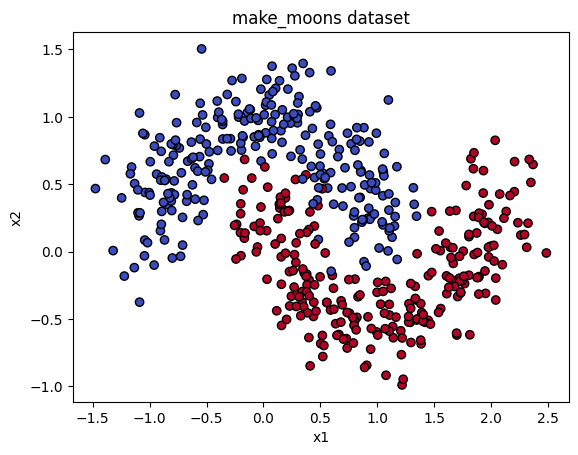

In [4]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
y = y.reshape(-1,1)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Visualize
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap='coolwarm', edgecolor='k')
plt.title("make_moons dataset")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()


In [5]:
print(X[:5])
print("="*50)
print(y[:5])

[[ 0.83085779 -0.33434228]
 [ 0.99170955  0.87899966]
 [ 1.1072453  -0.47034376]
 [-0.14089918  1.03314844]
 [ 0.40559217  1.32852876]]
[[1]
 [0]
 [1]
 [0]
 [0]]


### 3. Split into Train / Validation / Test

- **Train (70%)** → used to update weights
- **Validation (10%)** → used to monitor training and tune hyperparameters
- **Test (20%)** → used **only once** at the end for final evaluation

In [6]:
# First split: separate test set (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split: train (70%) and validation (10%) from the remaining 80%
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=42  # 0.125 * 0.8 = 0.1
)

print(f"Train: {X_train.shape[0]} samples")
print(f"Val:   {X_val.shape[0]} samples")
print(f"Test:  {X_test.shape[0]} samples")

Train: 350 samples
Val:   50 samples
Test:  100 samples


### 4. Activation Function (Sigmoid)

Squashes any number into the range (0, 1).

- **Sigmoid:** $\sigma(z) = \frac{1}{1 + e^{-z}}$ — outputs (0, 1), used at the **output** for binary classification.
  - Example: `z = 2` → `0.88` | `z = -2` → `0.12`

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # 'a' is already sigmoid(z)
    return a * (1 - a)

### 5. Initialize Weights and Biases

Three weight matrices for our 3-layer network:
- `W1`: input → hidden 1
- `W2`: hidden 1 → hidden 2
- `W3`: hidden 2 → output

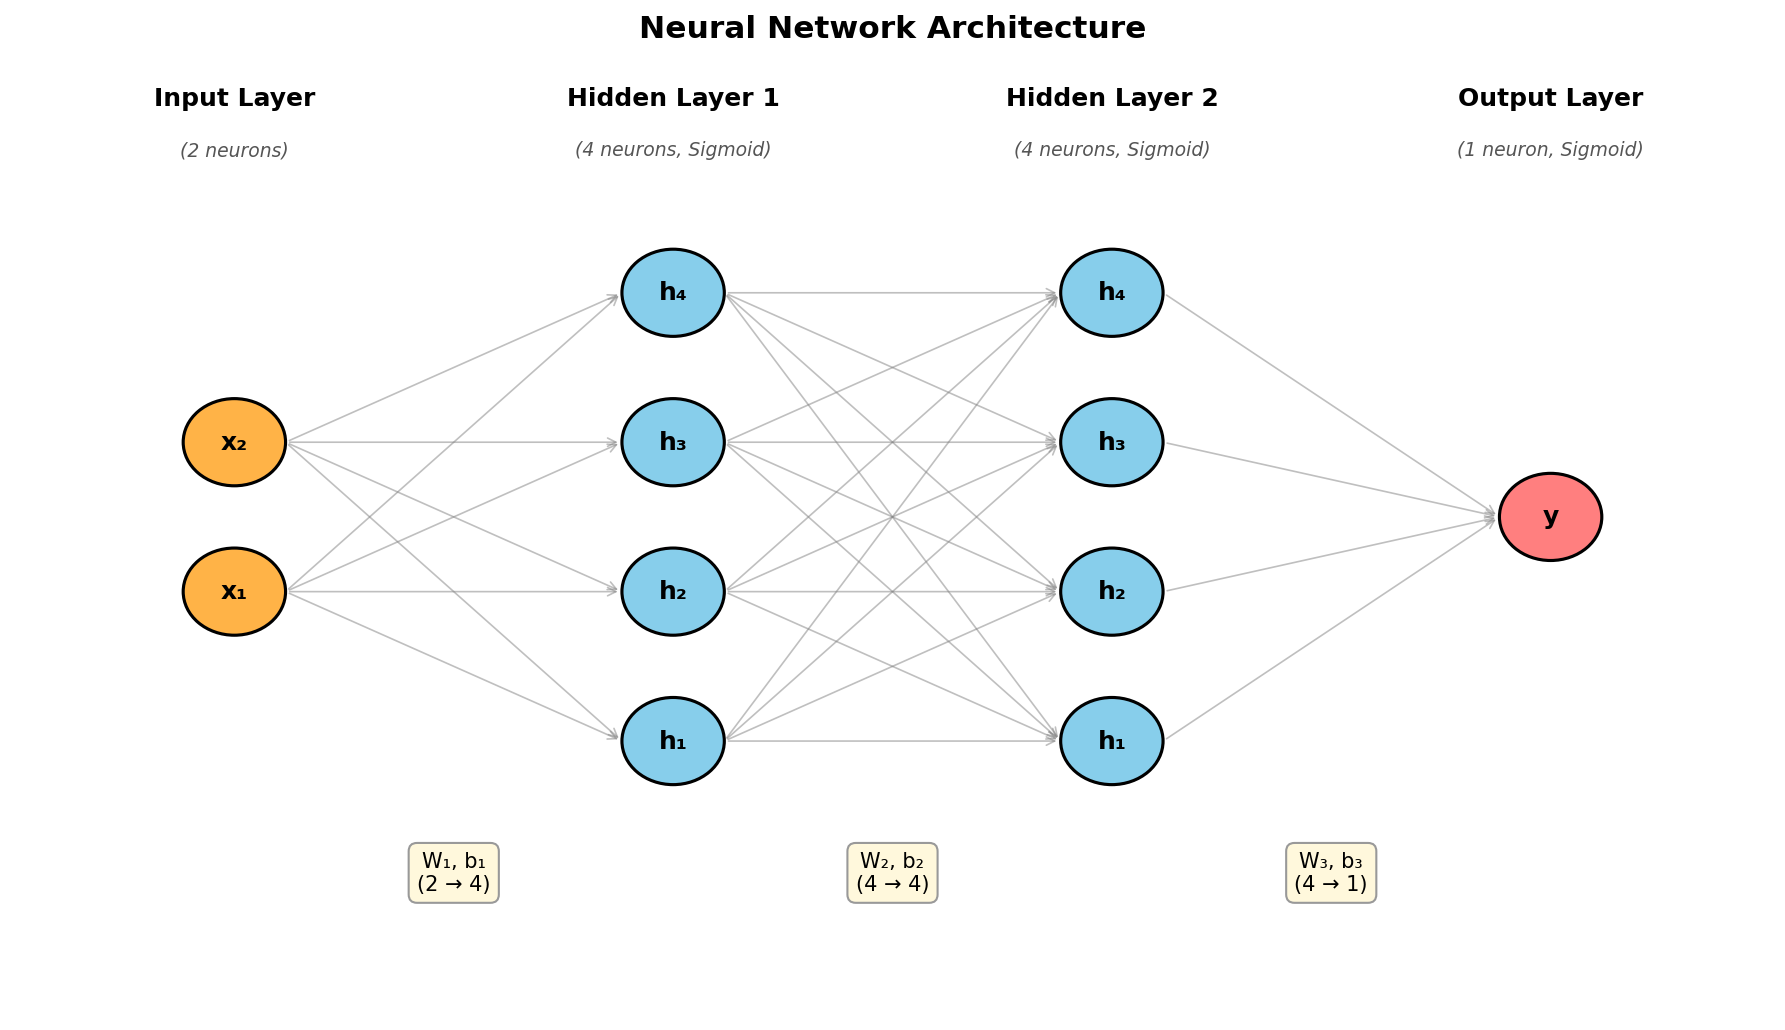

In [8]:
input_size = 2
hidden1_size = 4
hidden2_size = 4
output_size = 1

W1 = np.random.randn(input_size, hidden1_size) * 0.5
b1 = np.zeros((1, hidden1_size))

W2 = np.random.randn(hidden1_size, hidden2_size) * 0.5
b2 = np.zeros((1, hidden2_size))

W3 = np.random.randn(hidden2_size, output_size) * 0.5
b3 = np.zeros((1, output_size))

print("W1:", W1.shape, "| W2:", W2.shape, "| W3:", W3.shape)

W1: (2, 4) | W2: (4, 4) | W3: (4, 1)


### 6. Training Loop

Each epoch we do:
1. **Forward pass** on training data → compute predictions
2. **Loss** → measure error (Binary Cross-Entropy - BCE)
3. **Backward pass** → compute gradients (chain rule)
4. **Update** → adjust weights using gradient descent
5. **Validate** → compute loss on validation data (no weight update)

### Forward Pass

A 3-layer network (2 hidden + 1 output), all with sigmoid activation $\sigma(z) = \dfrac{1}{1 + e^{-z}}$.

$$
\begin{aligned}
z^{[1]} &= X W^{[1]} + b^{[1]} & a^{[1]} &= \sigma(z^{[1]}) \\
z^{[2]} &= a^{[1]} W^{[2]} + b^{[2]} & a^{[2]} &= \sigma(z^{[2]}) \\
z^{[3]} &= a^{[2]} W^{[3]} + b^{[3]} & a^{[3]} &= \sigma(z^{[3]}) \quad (\hat{y})
\end{aligned}
$$

### Loss — Binary Cross-Entropy

For $N$ samples, with $\epsilon$ added inside the logs for numerical stability:

$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \Big[\, y_i \log(a^{[3]}_i + \epsilon) + (1 - y_i)\log(1 - a^{[3]}_i + \epsilon) \,\Big]
$$

### Backward Pass

**Output layer.** Pairing sigmoid with BCE makes the gradient collapse to a clean difference — the $\sigma'(z)$ term from the chain rule cancels exactly against the denominator of the BCE derivative. *This is why sigmoid + BCE are paired together:*

$$
\frac{\partial \mathcal{L}}{\partial z^{[3]}} = \frac{a^{[3]} - y}{N}
$$

$$
dW^{[3]} = (a^{[2]})^\top \, dz^{[3]}, \qquad
db^{[3]} = \sum_{i} dz^{[3]}_i
$$

> Note: the $\tfrac{1}{N}$ averaging is folded into $dz^{[3]}$, so the layers below inherit it automatically — no extra division needed.

**Hidden layer 2.** Here the sigmoid derivative does *not* cancel, so we apply it explicitly. With $\sigma'(z) = a(1-a)$ where $a = \sigma(z)$:

$$
dz^{[2]} = \big(dz^{[3]} (W^{[3]})^\top\big) \odot \sigma'(a^{[2]})
$$

$$
dW^{[2]} = (a^{[1]})^\top \, dz^{[2]}, \qquad
db^{[2]} = \sum_{i} dz^{[2]}_i
$$

**Hidden layer 1.**

$$
dz^{[1]} = \big(dz^{[2]} (W^{[2]})^\top\big) \odot \sigma'(a^{[1]})
$$

$$
dW^{[1]} = X^\top \, dz^{[1]}, \qquad
db^{[1]} = \sum_{i} dz^{[1]}_i
$$

Here $\odot$ is element-wise (Hadamard) multiplication, and $\sigma'(a) = a \odot (1 - a)$.

### Gradient Descent Update

$$
W^{[l]} \leftarrow W^{[l]} - \eta \, dW^{[l]}, \qquad
b^{[l]} \leftarrow b^{[l]} - \eta \, db^{[l]}, \qquad l = 1, 2, 3
$$

with learning rate $\eta = 1.0$.

In [10]:
learning_rate = 1.0
epochs = 2000
train_losses = []
val_losses = []
epsilon = 1e-15  # for numerical stability in log

for epoch in range(epochs):
    # ---- Forward pass on TRAIN ----
    z1 = X_train @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    z3 = a2 @ W3 + b3
    a3 = sigmoid(z3)        # final prediction

    # ---- Train Loss (Binary Cross-Entropy) ----
    train_loss = -np.mean(y_train * np.log(a3 + epsilon) +
                          (1 - y_train) * np.log(1 - a3 + epsilon))
    train_losses.append(train_loss)

    # ---- Backward pass ----
    # Output layer: with sigmoid + BCE, the gradient simplifies beautifully to (a3 - y)
    # (the sigmoid derivative cancels out — this is why we pair them!)
    dz3 = (a3 - y_train) / len(y_train)
    dW3 = a2.T @ dz3
    db3 = np.sum(dz3, axis=0, keepdims=True)

    # Hidden layer 2
    dz2 = (dz3 @ W3.T) * sigmoid_derivative(a2)
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Hidden layer 1
    dz1 = (dz2 @ W2.T) * sigmoid_derivative(a1)
    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # ---- Update weights ----
    W3 -= learning_rate * dW3;  b3 -= learning_rate * db3
    W2 -= learning_rate * dW2;  b2 -= learning_rate * db2
    W1 -= learning_rate * dW1;  b1 -= learning_rate * db1

    # ---- Validation Loss (forward pass only, no update) ----
    a1_v = sigmoid(X_val @ W1 + b1)
    a2_v = sigmoid(a1_v @ W2 + b2)
    a3_v = sigmoid(a2_v @ W3 + b3)
    val_loss = -np.mean(y_val * np.log(a3_v + epsilon) +
                        (1 - y_val) * np.log(1 - a3_v + epsilon))
    val_losses.append(val_loss)

    if epoch % 200 == 0:
        print(f"Epoch {epoch:5d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch     0 | Train Loss: 0.6988 | Val Loss: 0.6965
Epoch   200 | Train Loss: 0.3497 | Val Loss: 0.2265
Epoch   400 | Train Loss: 0.3124 | Val Loss: 0.1701
Epoch   600 | Train Loss: 0.2990 | Val Loss: 0.1699
Epoch   800 | Train Loss: 0.2084 | Val Loss: 0.1280
Epoch  1000 | Train Loss: 0.1181 | Val Loss: 0.0597
Epoch  1200 | Train Loss: 0.0882 | Val Loss: 0.0365
Epoch  1400 | Train Loss: 0.0748 | Val Loss: 0.0291
Epoch  1600 | Train Loss: 0.0682 | Val Loss: 0.0280
Epoch  1800 | Train Loss: 0.0642 | Val Loss: 0.0286


### 7. Plot Training vs Validation Loss

If both curves go down together → healthy training.
If train keeps dropping while val flattens or rises → overfitting.

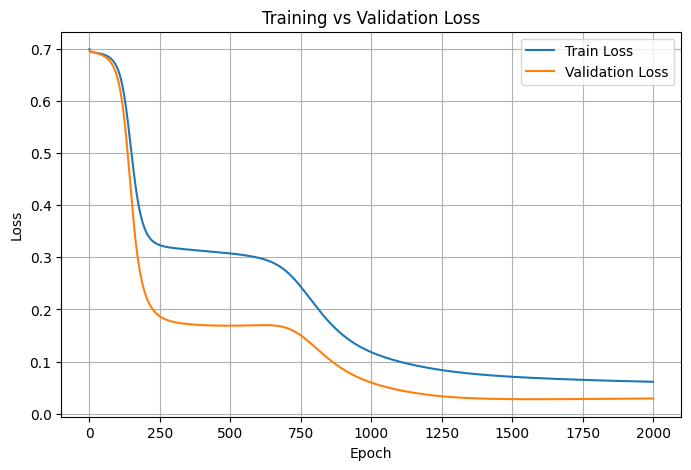

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend(); plt.grid(True)
plt.show()

### 8. Evaluate on Test Set

Final unbiased evaluation — the test set has never been seen during training.

In [12]:
def predict(X_input):
    a1 = sigmoid(X_input @ W1 + b1)
    a2 = sigmoid(a1 @ W2 + b2)
    a3 = sigmoid(a2 @ W3 + b3)
    return a3

# Accuracy on each splitW1
for name, X_, y_ in [("Train", X_train, y_train),
                     ("Val",   X_val,   y_val),
                     ("Test",  X_test,  y_test)]:
    preds = predict(X_)
    predicted_classes = (preds > 0.5).astype(int)
    accuracy = np.mean(predicted_classes == y_) * 100
    print(f"{name:5s} Accuracy: {accuracy:.2f}%")

Train Accuracy: 97.71%
Val   Accuracy: 98.00%
Test  Accuracy: 99.00%


### 9. Visualize the Decision Boundary

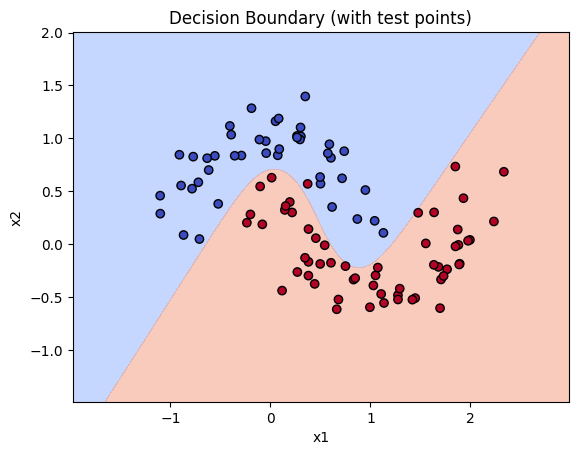

In [13]:
# Create a grid of points covering the data
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

# Predict for each grid point
zz = predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], cmap='coolwarm', alpha=0.5)
# Plot test set points to show how well boundary generalizes
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(),
            cmap='coolwarm', edgecolor='k')
plt.title("Decision Boundary (with test points)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()